# Sampling: Examples and Simulations

This notebook demonstrates random selection, stratified sampling, sampling variability, and sample means.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
print('NumPy version:', np.__version__)


NumPy version: 2.3.5


## 1. Population, sample, and statistics

In [2]:
population = np.arange(1, 101)
sample = rng.choice(population, size=10, replace=False)
print('Sample:', sample)
print('Population size:', len(population))
print('Sample size:', len(sample))
print('Sample mean:', round(sample.mean(), 3))
print('Population mean:', round(population.mean(), 3))


Sample: [97 72  9 61 42 95 69 10 20 83]
Population size: 100
Sample size: 10
Sample mean: 55.8
Population mean: 50.5


## 2. Sampling with and without replacement

In [3]:
with_replacement = rng.choice(population, size=20, replace=True)
without_replacement = rng.choice(population, size=20, replace=False)
print('Unique values with replacement:', len(np.unique(with_replacement)))
print('Unique values without replacement:', len(np.unique(without_replacement)))


Unique values with replacement: 18
Unique values without replacement: 20


## 3. Stratified sampling

In [4]:
group_a = np.arange(1, 81)
group_b = np.arange(101, 121)
sample_a = rng.choice(group_a, size=10, replace=False)
sample_b = rng.choice(group_b, size=5, replace=False)
stratified_sample = np.concatenate([sample_a, sample_b])
print('Group A sample size:', len(sample_a))
print('Group B sample size:', len(sample_b))
print('Combined sample size:', len(stratified_sample))


Group A sample size: 10
Group B sample size: 5
Combined sample size: 15


## 4. Sampling variability of the mean

In [5]:
source_population = rng.normal(loc=50, scale=12, size=20000)
means_10 = np.array([rng.choice(source_population, size=10, replace=False).mean() for _ in range(500)])
means_50 = np.array([rng.choice(source_population, size=50, replace=False).mean() for _ in range(500)])
means_200 = np.array([rng.choice(source_population, size=200, replace=False).mean() for _ in range(500)])
print('Population mean:', round(source_population.mean(), 3))
print('SD of sample means, n=10:', round(means_10.std(), 3))
print('SD of sample means, n=50:', round(means_50.std(), 3))
print('SD of sample means, n=200:', round(means_200.std(), 3))


Population mean: 50.066
SD of sample means, n=10: 3.618
SD of sample means, n=50: 1.652
SD of sample means, n=200: 0.875


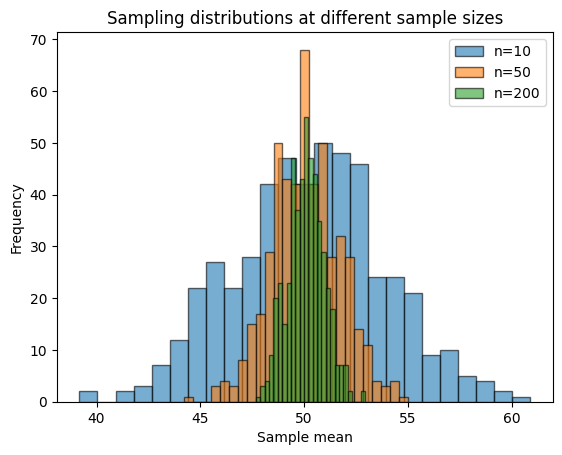

In [6]:
plt.hist(means_10, bins=25, alpha=0.6, label='n=10', edgecolor='black')
plt.hist(means_50, bins=25, alpha=0.6, label='n=50', edgecolor='black')
plt.hist(means_200, bins=25, alpha=0.6, label='n=200', edgecolor='black')
plt.xlabel('Sample mean')
plt.ylabel('Frequency')
plt.title('Sampling distributions at different sample sizes')
plt.legend()
plt.show()


## 5. Standard error and confidence interval illustration

In [7]:
observed = rng.choice(source_population, size=100, replace=False)
n = len(observed)
mean = observed.mean()
sd = observed.std(ddof=1)
se = sd / np.sqrt(n)
ci_low, ci_high = mean - 1.96 * se, mean + 1.96 * se
print('n:', n)
print('Sample mean:', round(mean, 3))
print('Sample SD:', round(sd, 3))
print('Estimated SE:', round(se, 3))
print('Approximate 95% interval:', (round(ci_low, 3), round(ci_high, 3)))


n: 100
Sample mean: 51.811
Sample SD: 11.997
Estimated SE: 1.2
Approximate 95% interval: (np.float64(49.459), np.float64(54.162))


This normal-based interval is illustrative. Small samples, non-normal data, complex sampling designs, and selection bias may require other methods or limit interpretation.

## 6. Approximate sample size for a mean

In [8]:
z_star = 1.96
sigma = 10
margin_of_error = 2
n_required = int(np.ceil((z_star * sigma / margin_of_error) ** 2))
print('Approximate required sample size:', n_required)


Approximate required sample size: 97


## Key takeaways

- The sample design determines what can be inferred about a population.
- Random sampling variability is different from systematic selection bias.
- Larger samples usually improve precision, but do not automatically make a biased sample representative.
- Report how the sample was selected and its limitations.